# Week 4: Consumer Complaint Patterns and Response Trends

**AnalystLab Africa · Experience Lab Internship · Data Science Track** · **Author:** Molemi Molokoane

**Dataset:** CFPB consumer complaints about Bank of America, 1 May 2017 to 28 August 2023 (`Consumer_Complaints.xlsx`, 62,516 records, and `ConsumerComplaints_DataDictionary.csv`), supplied by AnalystLab Africa.

**Research question:** *How have complaint volumes, products, recorded company responses and CFPB forwarding intervals changed between 2017 and 2023, and which of these differences are statistically supported?*

> A complaint is an issue *reported by a consumer*. It does not establish misconduct, and a recorded company response is not proof that a complaint was resolved satisfactorily. All findings below describe recorded data only.

### Workflow
1. Business understanding and hypotheses
2. Data inspection
3. Data preparation and cleaning log
4. Exploratory data analysis
5. Hypothesis tests (H1 to H4)
6. Validation
7. Limitations and alternative explanations
8. Findings and recommendations

## 1. Business understanding

Bank of America's complaint and compliance teams need to know where consumers report problems, whether that is changing, and how recorded responses and timeliness look over time. This analysis supports the shared Week 4 platform: the cleaned dataset and KPI definitions produced here are the common inputs for the dashboard, forecasting and AI-assistant tracks.

### Hypotheses

| | Question | Null hypothesis (H₀) | Test |
|---|---|---|---|
| **H1** | Did monthly complaint volume change across years? | Monthly volumes have the same distribution in every year; there is no monotonic trend | Kruskal-Wallis on full-month counts; Mann-Kendall trend test |
| **H2** | Is the recorded company response associated with the product? | Response category is independent of product | Chi-square test of independence, Cramér's V |
| **H3** | Did the timely-response rate change over time? | The timely share is the same in every year | Chi-square test with standardised residuals |
| **H4** | Do CFPB forwarding intervals differ by product? | Forwarding intervals have the same distribution for every product | Kruskal-Wallis with ε²; chi-square on the same-day share |

With about 62,000 records, even trivial differences will be statistically significant, so every test is reported with an **effect size** and interpreted on that basis. A 5% significance level is used, with Holm correction wherever several comparisons are made.

### Data interpretation rules (from the brief)
- `Date submitted` = the date the CFPB **received** the complaint. `Date received` = the date the CFPB **sent** it to the company.
- Their difference is the **CFPB forwarding interval**, not the company's response or resolution time.
- A blank `Timely response?` is **not** a "No". In this data it only occurs on complaints still marked *In progress*.
- The timely-response rate uses only Yes/No records in the denominator; excluded records are reported separately.

### Success criteria
- Every brief data-preparation step is done and documented, and the raw file is provably unchanged.
- Each hypothesis is tested with assumptions checked, and interpreted with an effect size.
- Key figures reconcile with an independent recalculation.
- At least three findings are supported by evidence, with limitations stated.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT = Path.cwd()
sys.path.insert(0, str(PROJECT))
import complaint_prep as cp

DATA = PROJECT / "Data"
RAW_FILE = DATA / "Consumer_Complaints.xlsx"
DICT_FILE = DATA / "ConsumerComplaints_DataDictionary.csv"
CLEAN_DIR = DATA / "Cleaned"
OUT = PROJECT / "Outputs"
VIS = PROJECT / "Visualizations"
for folder in (CLEAN_DIR, OUT, VIS):
    folder.mkdir(exist_ok=True)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

## 2. Data inspection

### 2.1 Load the raw file and record its fingerprint
The SHA-256 hash is recorded before any work and checked again at the end of the notebook, to show the original dataset is preserved.

In [2]:
RAW_HASH_BEFORE = cp.file_sha256(RAW_FILE)
print("SHA-256:", RAW_HASH_BEFORE)
print("Worksheets:", pd.ExcelFile(RAW_FILE).sheet_names)

raw = cp.load_raw(RAW_FILE)
print(f"Shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

SHA-256: FCD270456EB9363482DA7136CF7915A4ED21FF705F31EFF995A0807B85B5E5F6


Worksheets: ['Data']


Shape: 62,516 rows x 12 columns


,Complaint ID,Submitted via,Date submitted,Date received,State,Product,Sub-product,Issue,Sub-issue,Company public response,Company response to consumer,Timely response?
0,4848023,Referral,2021-10-24,2021-10-27,NY,Mortgage,Conventional home mortgage,Applying for a mortgage or refinancing an existing mortgage,NaN,Company has responded to the consumer and the CFPB and chooses not to provid...,Closed with explanation,Yes
1,3621464,Web,2020-04-24,2020-04-24,FL,"Money transfer, virtual currency, or money service",Refund anticipation check,Lost or stolen check,NaN,Company has responded to the consumer and the CFPB and chooses not to provid...,Closed with monetary relief,Yes
2,5818349,Web,2022-07-27,2022-07-27,CA,"Credit reporting, credit repair services, or other personal consumer reports",Credit reporting,Incorrect information on your report,Account information incorrect,Company has responded to the consumer and the CFPB and chooses not to provid...,Closed with explanation,Yes
3,7233015,Referral,2023-07-10,2023-07-11,CA,Credit card or prepaid card,General-purpose prepaid card,Problem getting a card or closing an account,"Trouble getting, activating, or registering a card",NaN,In progress,NaN
4,5820224,Referral,2022-07-27,2022-07-28,VA,Credit card or prepaid card,General-purpose credit card or charge card,Closing your account,Company closed your account,Company has responded to the consumer and the CFPB and chooses not to provid...,Closed with explanation,Yes


### 2.2 Structure, column types and the data dictionary

In [3]:
dictionary = pd.read_csv(DICT_FILE)
structure = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "missing_pct": (100 * raw.isna().mean()).round(2),
    "unique": raw.nunique(),
})
structure["in_dictionary"] = structure.index.isin(dictionary["Field"])
structure

,dtype,non_null,missing,missing_pct,unique,in_dictionary
Complaint ID,int64,62516,0,0.00,62516,True
Submitted via,str,62516,0,0.00,7,True
Date submitted,datetime64[us],62516,0,0.00,2308,True
Date received,datetime64[us],62516,0,0.00,2305,True
State,str,62516,0,0.00,51,True
Product,str,62516,0,0.00,9,True
Sub-product,str,62509,7,0.01,46,True
Issue,str,62516,0,0.00,76,True
Sub-issue,str,51658,10858,17.37,158,True
Company public response,str,60341,2175,3.48,6,True


All 12 columns match the brief and the data dictionary. Both date columns load as true dates and `Complaint ID` as an integer. The dictionary has a small typo (*"oossible"* in the Sub-issue description), which does not affect the analysis.

### 2.3 Uniqueness of Complaint ID and duplicate records

In [4]:
content_dup = cp.content_duplicate_mask(raw)
dup_groups = raw[content_dup].groupby([c for c in raw.columns if c != "Complaint ID"], dropna=False).size()
print("Complaint ID unique:           ", raw["Complaint ID"].is_unique)
print("Exact duplicate rows:          ", raw.duplicated().sum())
print(f"Rows identical except for ID:   {content_dup.sum():,} in {len(dup_groups):,} groups "
      f"(group size: median {dup_groups.median():.0f}, max {dup_groups.max()})")
raw.loc[content_dup, "Product"].value_counts().to_frame("rows in duplicate groups")

Complaint ID unique:            True
Exact duplicate rows:           0
Rows identical except for ID:   2,784 in 1,290 groups (group size: median 2, max 9)


,rows in duplicate groups
Product,
"Credit reporting, credit repair services, or other personal consumer reports",978
Checking or savings account,750
Credit card or prepaid card,567
Debt collection,215
Mortgage,193
"Money transfer, virtual currency, or money service",79
Vehicle loan or lease,2


**Decision: keep the 2,784 look-alike rows.** They have distinct complaint IDs, and the dataset has no consumer identifier or narrative, only a date, state and a few categories. Two different consumers in the same state reporting the same product and issue on the same day will produce identical rows, especially in high-volume categories such as credit reporting. Removing them would undercount complaints. They are flagged (`content_duplicate`) so their influence can be checked in the validation section.

### 2.4 Missing values and what they mean

In [5]:
in_progress = raw["Company response to consumer"].eq(cp.IN_PROGRESS)
missing = pd.DataFrame({
    "missing": raw.isna().sum(),
    "of_which_in_progress": raw[in_progress].isna().sum(),
}).query("missing > 0")
missing["of_which_closed"] = missing["missing"] - missing["of_which_in_progress"]
missing

,missing,of_which_in_progress,of_which_closed
Sub-product,7,0,7
Sub-issue,10858,160,10698
Company public response,2175,1494,681
Timely response?,1494,1494,0


In [6]:
print("Blank 'Timely response?' rows that are In progress:",
      raw["Timely response?"].isna().equals(in_progress))
print("In-progress complaints submitted between",
      raw.loc[in_progress, "Date submitted"].min().date(), "and",
      raw.loc[in_progress, "Date submitted"].max().date())
pd.crosstab(raw["Timely response?"].fillna("(blank)"), raw["Company response to consumer"], margins=True)

Blank 'Timely response?' rows that are In progress: True
In-progress complaints submitted between 2023-05-12 and 2023-08-28


Company response to consumer,Closed,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief,In progress,All
Timely response?,,,,,,
(blank),0,0,0,0,1494,1494
No,8,1527,690,178,0,2403
Yes,0,39517,14007,5095,0,58619
All,8,41044,14697,5273,1494,62516


- **Timely response?** All 1,494 blanks are *In progress* complaints, all submitted after 12 May 2023. They are labelled *Pending* and kept out of the timely-rate denominator.
- **Company public response:** 1,494 blanks are In progress (no response yet). The other 681 are closed complaints with no public response recorded. The public response is optional, so these are labelled *Not recorded*, not treated as errors.
- **Sub-issue** (10,858) and **Sub-product** (7): the dictionary says not every issue has a sub-issue and not every product a sub-product. Blanks are labelled, not imputed.

In [7]:
raw.loc[raw["Sub-product"].isna(), ["Product", "Issue"]]

,Product,Issue
5623,Checking or savings account,Incorrect information on your report
14554,Checking or savings account,Problem with a credit reporting company's investigation into an existing pro...
39878,Checking or savings account,Incorrect information on your report
40582,Checking or savings account,Problem with a credit reporting company's investigation into an existing pro...
42790,Checking or savings account,Incorrect information on your report
55010,Checking or savings account,Incorrect information on your report
62288,Checking or savings account,Incorrect information on your report


The 7 rows without a sub-product are all checking or savings accounts reporting *credit report* issues, which look like miscategorised complaints. They are too few to matter and are kept as filed.

### 2.5 Date validation

In [8]:
fwd = (raw["Date received"] - raw["Date submitted"]).dt.days
date_checks = pd.Series({
    "earliest Date submitted": raw["Date submitted"].min().date(),
    "latest Date submitted": raw["Date submitted"].max().date(),
    "earliest Date received": raw["Date received"].min().date(),
    "latest Date received": raw["Date received"].max().date(),
    "rows with a time component": int(((raw["Date submitted"] != raw["Date submitted"].dt.normalize()) |
                                       (raw["Date received"] != raw["Date received"].dt.normalize())).sum()),
    "forwarded before submitted (negative interval)": int((fwd < 0).sum()),
    "forwarded the same day": int((fwd == 0).sum()),
    f"interval > {cp.LONG_FORWARDING_DAYS} days": int((fwd > cp.LONG_FORWARDING_DAYS).sum()),
    "longest interval (days)": int(fwd.max()),
}, name="value").to_frame()
date_checks

,value
earliest Date submitted,2017-05-01
latest Date submitted,2023-08-28
earliest Date received,2017-05-01
latest Date received,2023-08-28
rows with a time component,0
forwarded before submitted (negative interval),0
forwarded the same day,49634
interval > 30 days,435
longest interval (days),275


Dates fall exactly in the stated range, and no complaint was forwarded before it was received. Intervals above 30 days (435 complaints) are plausible operational delays, so they are flagged for analysis, not removed.

### 2.6 Reporting months: gaps and partial periods

In [9]:
month = raw["Date submitted"].dt.to_period("M")
per_month = raw.groupby(month)["Date submitted"].agg(
    complaints="size", first_day="min", last_day="max",
    days_with_complaints=lambda s: s.dt.day.nunique())
all_months = pd.period_range(per_month.index.min(), per_month.index.max(), freq="M")
print(f"{len(per_month)} months with data out of {len(all_months)} in range; "
      f"missing months: {sorted(set(all_months) - set(per_month.index)) or 'none'}")
print(f"Monthly volume: median {per_month['complaints'].median():.0f}, "
      f"min {per_month['complaints'].min()}, max {per_month['complaints'].max()}")
pd.concat([per_month.head(2), per_month.tail(3)])

76 months with data out of 76 in range; missing months: none
Monthly volume: median 749, min 356, max 1749


,complaints,first_day,last_day,days_with_complaints
Date submitted,,,,
2017-05,744,2017-05-01,2017-05-31,31
2017-06,701,2017-06-01,2017-06-30,30
2023-06,1018,2023-06-01,2023-06-30,30
2023-07,1749,2023-07-01,2023-07-31,31
2023-08,717,2023-08-01,2023-08-28,26


- **August 2023** ends on the 28th, so it is a partial month.
- **May 2017** has complaints on all 31 days and a typical volume (744), so the data suggests it is complete. The brief treats the first and last months as partial, so **both are excluded from month-level tests** (H1). That costs only one possibly complete month.
- **July 2023** is the busiest month (1,749, against a median of 749). The daily counts below show whether this comes from one day or is spread across the month.

In [10]:
july = raw.loc[month == "2023-07", "Date submitted"].dt.date.value_counts().sort_index()
print(f"July 2023 daily complaints: median {july.median():.0f}, max {july.max()} on {july.idxmax()}")
july.sort_values(ascending=False).head(5).to_frame("complaints")

July 2023 daily complaints: median 53, max 183 on 2023-07-12


,complaints
Date submitted,
2023-07-12,183
2023-07-13,148
2023-07-11,108
2023-07-14,98
2023-07-15,81


The July 2023 peak is **not** spread across the month: 11 to 14 July alone account for 537 complaints, against a typical 53 a day. A short burst like this points to a one-off trigger (for example news coverage or a regulatory announcement concerning the bank) rather than a change in underlying service. The dataset cannot show the cause, so the month is **kept** as genuine recorded volume and treated as an outlier in interpretation, not removed.

### 2.7 Categorical consistency

In [11]:
category_checks = []
for col in cp.TEXT_COLUMNS:
    values = raw[col].dropna().astype(str)
    category_checks.append({
        "column": col,
        "distinct_values": values.nunique(),
        "with_extra_spaces": int((values != values.str.strip()).sum()),
        "case_or_space_variants": values.nunique() - values.str.strip().str.lower().nunique(),
    })
pd.DataFrame(category_checks).set_index("column")

,distinct_values,with_extra_spaces,case_or_space_variants
column,,,
Submitted via,7,0,0
State,51,0,0
Product,9,0,0
Sub-product,46,0,0
Issue,76,0,0
Sub-issue,158,0,0
Company public response,6,0,0
Company response to consumer,5,0,0
Timely response?,2,0,0


In [12]:
for col in ["Submitted via", "Product", "Company response to consumer", "Company public response", "Timely response?"]:
    display(raw[col].value_counts(dropna=False).to_frame(col))

,Submitted via
Submitted via,
Web,45423
Referral,10766
Phone,4684
Postal mail,1318
Fax,233
Web Referral,90
Email,2


,Product
Product,
Checking or savings account,24814
Credit card or prepaid card,16197
"Credit reporting, credit repair services, or other personal consumer reports",7710
Mortgage,6601
"Money transfer, virtual currency, or money service",3453
Debt collection,2736
Vehicle loan or lease,633
"Payday loan, title loan, or personal loan",333
Student loan,39


,Company response to consumer
Company response to consumer,
Closed with explanation,41044
Closed with monetary relief,14697
Closed with non-monetary relief,5273
In progress,1494
Closed,8


,Company public response
Company public response,
Company has responded to the consumer and the CFPB and chooses not to provide a public response,60311
NaN,2175
Company believes the complaint provided an opportunity to answer consumer's questions,12
Company believes the complaint is the result of a misunderstanding,7
Company believes it acted appropriately as authorized by contract or law,6
Company believes complaint caused principally by actions of third party outside the control or direction of the company,3
Company disputes the facts presented in the complaint,2


,Timely response?
Timely response?,
Yes,58619
No,2403
NaN,1494


No category has spelling, spacing or case variants, so no values need merging. Points worth noting:
- **Submitted via:** *Web Referral* (90) and *Email* (2) are small but legitimate CFPB channel values; they are kept as recorded.
- **Company response to consumer:** *Closed* without further detail has only 8 records, all marked untimely. It is kept as its own category.
- **Company public response:** 96.5% of records are *"chooses not to provide a public response"*. Only 30 records carry a substantive public statement, too few for statistical analysis.
- **State:** 51 values (50 states plus DC); no territories or invalid codes.

## 3. Data preparation

All cleaning is done by `complaint_prep.clean()`, which is covered by unit tests (`tests/test_complaint_prep.py`). It **keeps every row and every raw column unchanged** and adds cleaned or derived values as new snake_case columns, so each value can be traced back to the original.

In [13]:
df, cleaning_log = cp.clean(raw)
cleaning_log

,step,column,rule,rows_affected,rationale
0,1,all text columns,Trim leading and trailing spaces,0,Prevents the same category from being counted twice; no case or spacing vari...
1,2,forwarding_days,"Date received minus Date submitted, in whole days",62516,CFPB forwarding interval; not the company's response time. No negative inter...
2,3,long_forwarding,Flag intervals above 30 days,435,"Kept, not removed: long intervals are plausible and are analysed as a group"
3,4,"year, quarter, month, year_month, year_quarter",Derived from Date submitted,62516,Volume is dated by when the CFPB received the complaint
4,5,boundary_month,Flag the first (2017-05) and last (2023-08) months,1461,The brief treats them as partial; excluded from month-level tests only
5,6,product_short,Short chart label for each product,62516,Full CFPB product names are kept in Product
6,7,sub_product,Blank -> 'Not specified',7,The dictionary says not all products have sub-products
7,8,sub_issue,Blank -> 'No sub-issue recorded',10858,The dictionary says not all issues have sub-issues; a blank is not missing data
8,9,public_response,Blank and In progress -> 'Pending (complaint in progress)',1494,"The company has not finished responding, so no public response is expected yet"
9,10,public_response,Blank and closed -> 'Not recorded',681,A public response is optional; a blank is not a refusal or a dispute


In [14]:
derived = [c for c in df.columns if c not in cp.RAW_COLUMNS]
print(f"{len(df):,} rows, {len(cp.RAW_COLUMNS)} raw columns + {len(derived)} derived columns:")
print(", ".join(derived))
df[derived].head()

62,516 rows, 12 raw columns + 19 derived columns:
date_submitted, date_received, forwarding_days, same_day_forwarding, long_forwarding, year, quarter, month, year_month, year_quarter, boundary_month, product_short, sub_product, sub_issue, in_progress, public_response, timely_status, timely, content_duplicate


,date_submitted,date_received,forwarding_days,same_day_forwarding,long_forwarding,year,quarter,month,year_month,year_quarter,boundary_month,product_short,sub_product,sub_issue,in_progress,public_response,timely_status,timely,content_duplicate
0,2021-10-24,2021-10-27,3,False,False,2021,4,10,2021-10,2021Q4,False,Mortgage,Conventional home mortgage,No sub-issue recorded,False,Company has responded to the consumer and the CFPB and chooses not to provid...,Yes,True,False
1,2020-04-24,2020-04-24,0,True,False,2020,2,4,2020-04,2020Q2,False,Money transfer,Refund anticipation check,No sub-issue recorded,False,Company has responded to the consumer and the CFPB and chooses not to provid...,Yes,True,False
2,2022-07-27,2022-07-27,0,True,False,2022,3,7,2022-07,2022Q3,False,Credit reporting,Credit reporting,Account information incorrect,False,Company has responded to the consumer and the CFPB and chooses not to provid...,Yes,True,False
3,2023-07-10,2023-07-11,1,False,False,2023,3,7,2023-07,2023Q3,False,Credit/prepaid card,General-purpose prepaid card,"Trouble getting, activating, or registering a card",True,Pending (complaint in progress),Pending (in progress),<NA>,False
4,2022-07-27,2022-07-28,1,False,False,2022,3,7,2022-07,2022Q3,False,Credit/prepaid card,General-purpose credit card or charge card,Company closed your account,False,Company has responded to the consumer and the CFPB and chooses not to provid...,Yes,True,False


### 3.1 Validation after cleaning
These checks stop the notebook if any cleaning step changed a count it should not have.

In [15]:
checks = {
    "row count unchanged": len(df) == len(raw) == 62_516,
    "Complaint ID still unique": df["Complaint ID"].is_unique,
    "raw columns unchanged": all(df[c].equals(raw[c]) for c in cp.RAW_COLUMNS),
    "no blanks in derived columns (except timely)": df[[c for c in derived if c != "timely"]].notna().all().all(),
    "timely blanks == In progress": df["timely"].isna().equals(df["in_progress"]),
    "Yes + No + Pending == total": sum(cp.timely_rate(df)[k] for k in ("yes", "no", "excluded_pending")) == len(df),
    "product shares sum to 100%": abs(cp.share_table(df, "Product")["pct"].sum() - 100) < 0.05,
    "monthly counts sum to total": cp.monthly_counts(df).sum() == len(df),
    "annual counts sum to total": cp.yoy_change(df)["complaints"].sum() == len(df),
    "forwarding interval never negative": (df["forwarding_days"] >= 0).all(),
    "76 months, none missing": len(cp.monthly_counts(df)) == 76 and (cp.monthly_counts(df) > 0).all(),
}
validation = pd.Series(checks, name="passed").to_frame()
assert validation["passed"].all(), validation[~validation["passed"]]
validation

,passed
row count unchanged,True
Complaint ID still unique,True
raw columns unchanged,True
no blanks in derived columns (except timely),True
timely blanks == In progress,True
Yes + No + Pending == total,True
product shares sum to 100%,True
monthly counts sum to total,True
annual counts sum to total,True
forwarding interval never negative,True


### 3.2 Headline KPIs on the cleaned data
Shared definitions for all tracks (also exported to `Outputs/kpi_definitions.csv`).

In [16]:
timely = cp.timely_rate(df)
forwarding = cp.forwarding_summary(df)
kpi_definitions = pd.DataFrame([
    ("Total complaints", "Count of unique Complaint IDs", f"{len(df):,}"),
    ("Complaint volume period", "Dated by Date submitted (when the CFPB received the complaint)",
     f"{df['date_submitted'].min().date()} to {df['date_submitted'].max().date()}"),
    ("Timely-response rate", "Yes / (Yes + No); In-progress (blank) records excluded and reported separately",
     f"{timely['timely_pct']:.2f}% ({timely['yes']:,} of {timely['denominator']:,}; "
     f"{timely['excluded_pending']:,} pending excluded)"),
    ("In-progress complaints", "Company response to consumer = 'In progress'", f"{int(df['in_progress'].sum()):,}"),
    ("Forwarding interval", "Date received minus Date submitted, in days (CFPB to company; not company response time)",
     f"mean {forwarding['mean_days']:.2f} days, median {forwarding['median_days']:.0f}"),
    ("Same-day forwarding", "Share of complaints with a forwarding interval of 0 days", f"{forwarding['same_day_pct']:.1f}%"),
    ("Unusually long forwarding", f"Forwarding interval > {cp.LONG_FORWARDING_DAYS} days",
     f"{forwarding['long_count']:,} complaints"),
    ("Product share", "Complaints for a product / total complaints", "see Outputs/product_share.csv"),
    ("Year-over-year change", "Change in annual complaints; 2017 and 2023 are partial years, so per-month averages are also compared",
     "see Outputs/annual_volume.csv"),
], columns=["kpi", "definition", "value"]).set_index("kpi")
kpi_definitions

,definition,value
kpi,,
Total complaints,Count of unique Complaint IDs,"62,516"
Complaint volume period,Dated by Date submitted (when the CFPB received the complaint),2017-05-01 to 2023-08-28
Timely-response rate,Yes / (Yes + No); In-progress (blank) records excluded and reported separately,"96.06% (58,619 of 61,022; 1,494 pending excluded)"
In-progress complaints,Company response to consumer = 'In progress',"1,494"
Forwarding interval,"Date received minus Date submitted, in days (CFPB to company; not company re...","mean 1.22 days, median 0"
Same-day forwarding,Share of complaints with a forwarding interval of 0 days,79.4%
Unusually long forwarding,Forwarding interval > 30 days,435 complaints
Product share,Complaints for a product / total complaints,see Outputs/product_share.csv
Year-over-year change,"Change in annual complaints; 2017 and 2023 are partial years, so per-month a...",see Outputs/annual_volume.csv


In [17]:
cp.yoy_change(df)

,complaints,months,complaints_per_month,yoy_change_pct,yoy_change_per_month_pct,partial_year
year,,,,,,
2017,5394,8,674.2,NaN,NaN,True
2018,7872,12,656.0,45.9,-2.7,False
2019,7075,12,589.6,-10.1,-10.1,False
2020,8942,12,745.2,26.4,26.4,False
2021,11149,12,929.1,24.7,24.7,False
2022,12953,12,1079.4,16.2,16.2,False
2023,9131,8,1141.4,-29.5,5.7,True


### 3.3 Exports
- `Data/Cleaned/complaints_clean.csv`: the cleaned dataset (raw columns plus derived columns), for the dashboard, forecasting and AI-assistant tracks.
- `Outputs/cleaning_log.csv`, `Outputs/data_quality_summary.csv`, `Outputs/kpi_definitions.csv`, `Outputs/product_share.csv`, `Outputs/annual_volume.csv`.

In [18]:
df.to_csv(CLEAN_DIR / "complaints_clean.csv", index=False)
cleaning_log.to_csv(OUT / "cleaning_log.csv", index=False)
kpi_definitions.to_csv(OUT / "kpi_definitions.csv")
cp.share_table(df, "Product").to_csv(OUT / "product_share.csv")
cp.yoy_change(df).to_csv(OUT / "annual_volume.csv")

data_quality = pd.DataFrame([
    ("Records", len(raw), "Matches the brief (62,516)"),
    ("Columns", raw.shape[1], "Matches the brief and data dictionary"),
    ("Duplicate Complaint IDs", int(raw["Complaint ID"].duplicated().sum()), "Complaint ID is a valid primary key"),
    ("Exact duplicate rows", int(raw.duplicated().sum()), ""),
    ("Rows identical except Complaint ID", int(content_dup.sum()), "Kept and flagged; no consumer identifier exists"),
    ("Blank Sub-product", int(raw["Sub-product"].isna().sum()), "Labelled 'Not specified'"),
    ("Blank Sub-issue", int(raw["Sub-issue"].isna().sum()), "Labelled 'No sub-issue recorded'"),
    ("Blank public response (in progress)", int((raw["Company public response"].isna() & in_progress).sum()), "Labelled 'Pending'"),
    ("Blank public response (closed)", int((raw["Company public response"].isna() & ~in_progress).sum()), "Labelled 'Not recorded'"),
    ("Blank Timely response?", int(raw["Timely response?"].isna().sum()), "All In progress; excluded from timely rate"),
    ("Negative forwarding intervals", int((fwd < 0).sum()), ""),
    (f"Forwarding intervals > {cp.LONG_FORWARDING_DAYS} days", int((fwd > cp.LONG_FORWARDING_DAYS).sum()), "Kept and flagged"),
    ("Missing months in range", len(set(all_months) - set(per_month.index)), "76 of 76 months present"),
    ("Category spelling/case variants", int(sum(c["case_or_space_variants"] for c in category_checks)), "No standardisation needed"),
], columns=["check", "result", "action"])
data_quality.to_csv(OUT / "data_quality_summary.csv", index=False)
data_quality

,check,result,action
0,Records,62516,"Matches the brief (62,516)"
1,Columns,12,Matches the brief and data dictionary
2,Duplicate Complaint IDs,0,Complaint ID is a valid primary key
3,Exact duplicate rows,0,
4,Rows identical except Complaint ID,2784,Kept and flagged; no consumer identifier exists
5,Blank Sub-product,7,Labelled 'Not specified'
6,Blank Sub-issue,10858,Labelled 'No sub-issue recorded'
7,Blank public response (in progress),1494,Labelled 'Pending'
8,Blank public response (closed),681,Labelled 'Not recorded'
9,Blank Timely response?,1494,All In progress; excluded from timely rate


## 4. Exploratory data analysis

This section works through the brief's EDA activities in order:
- 4.1 annual and monthly volume
- 4.2 products and issues
- 4.3 how the product and issue mix changed over time
- 4.4 recorded company responses and timeliness
- 4.5 CFPB forwarding intervals

Each chart is saved to `Visualizations/` and its numbers to `Outputs/`, so the dashboard and report can reuse them. Section 5 tests these patterns formally; here they are only described.

All volumes are dated by `Date submitted`, the day the CFPB received the complaint. 2017 (May to December) and 2023 (January to 28 August) are partial years, so year-to-year comparisons use **complaints per month** or **shares**, not raw annual totals.

In [19]:
import textwrap

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgb
from matplotlib.ticker import FuncFormatter, PercentFormatter

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Same colours as Week 3: one colour for single-series charts and a fixed categorical order for
# multi-series charts (checked for colour-blind separation). Grey marks "Other" and partial years.
# Two of the colours have low contrast on white, so every chart also carries value labels and a table.
BAR_COLOR = "#2a78d6"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
OTHER = "#b4b4b0"
INK = "#0b0b0b"
thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")

PRODUCT_ORDER = df["product_short"].value_counts().index.tolist()  # largest first, used everywhere
TOP_PRODUCTS = PRODUCT_ORDER[:4]                                   # the rest fold into "Other"
YEARS = sorted(df["year"].unique())
year_labels = [f"{y}\n(May-Dec)" if y == 2017 else f"{y}\n(Jan-Aug)" if y == 2023 else str(y) for y in YEARS]


def wrap(label, width=38):
    return "\n".join(textwrap.wrap(str(label), width))


def label_color(fill):
    # Dark text on light fills, white text on dark fills
    r, g, b = to_rgb(fill)
    return INK if 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.45 else "white"


def save_fig(fig, name):
    # Save a chart to Visualizations/ and display it
    fig.savefig(VIS / name, bbox_inches="tight", dpi=150)
    plt.show()


def stacked_share_bars(ax, shares, colors, label_min=0.05, horizontal=False):
    # 100% stacked bars with a white gap between segments and labels on segments large enough to hold one
    start = np.zeros(len(shares))
    for col, color in zip(shares.columns, colors):
        values = shares[col].to_numpy()
        if horizontal:
            ax.barh(range(len(shares)), values, left=start, height=0.7, color=color, label=col,
                    edgecolor="white", linewidth=1.5)
        else:
            ax.bar(range(len(shares)), values, bottom=start, width=0.7, color=color, label=col,
                   edgecolor="white", linewidth=1.5)
        for i, (s, v) in enumerate(zip(start, values)):
            if v >= label_min:
                x, y = (s + v / 2, i) if horizontal else (i, s + v / 2)
                ax.text(x, y, f"{v:.0%}", ha="center", va="center", fontsize=8, color=label_color(color))
        start += values

### 4.1 Annual and monthly complaint volume

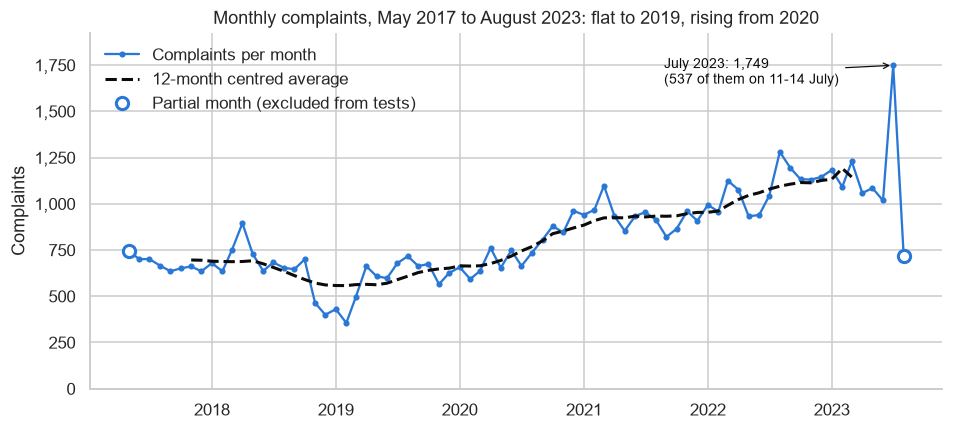

Monthly complaints (full months): median 756, IQR 655 to 962
Lowest full month: 2019-02 (356); highest: 2023-07 (1,749)


In [20]:
monthly = cp.monthly_counts(df)
monthly_full = cp.monthly_counts(df, full_months_only=True)
monthly_dates = pd.PeriodIndex(monthly.index, freq="M").to_timestamp()
rolling = monthly.rolling(12, center=True).mean()
boundary = [0, len(monthly) - 1]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(monthly_dates, monthly.values, color=BAR_COLOR, lw=1.5, marker="o", ms=3, label="Complaints per month")
ax.plot(monthly_dates, rolling.values, color=INK, lw=2, ls="--", label="12-month centred average")
ax.plot(monthly_dates[boundary], monthly.values[boundary], ls="none", marker="o", ms=8,
        mfc="white", mec=BAR_COLOR, mew=2, label="Partial month (excluded from tests)")
peak = monthly.idxmax()
ax.annotate(f"July 2023: {monthly.max():,}\n(537 of them on 11-14 July)",
            xy=(monthly_dates[monthly.index.get_loc(peak)], monthly.max()),
            xytext=(-150, -12), textcoords="offset points", fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="->", color=INK, lw=0.8))
ax.yaxis.set_major_formatter(thousands)
ax.set(ylabel="Complaints", ylim=(0, monthly.max() * 1.1),
       title="Monthly complaints, May 2017 to August 2023: flat to 2019, rising from 2020")
ax.legend(frameon=False, loc="upper left")
save_fig(fig, "01_monthly_volume.png")

monthly.to_frame().assign(rolling_12m=rolling.round(1)).to_csv(OUT / "monthly_volume.csv")
print(f"Monthly complaints (full months): median {monthly_full.median():.0f}, "
      f"IQR {monthly_full.quantile(.25):.0f} to {monthly_full.quantile(.75):.0f}")
print(f"Lowest full month: {monthly_full.idxmin()} ({monthly_full.min()}); "
      f"highest: {monthly_full.idxmax()} ({monthly_full.max():,})")

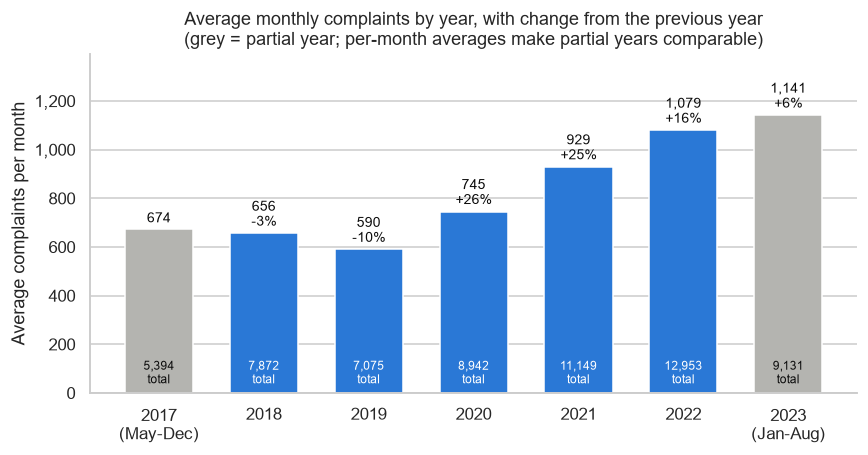

In [21]:
annual = cp.yoy_change(df)
fig, ax = plt.subplots(figsize=(9, 4))
colors = [OTHER if p else BAR_COLOR for p in annual["partial_year"]]
ax.bar(range(len(annual)), annual["complaints_per_month"], color=colors, width=0.65)
for i, (per_month, total, change) in enumerate(zip(annual["complaints_per_month"], annual["complaints"],
                                                   annual["yoy_change_per_month_pct"])):
    change_text = "" if pd.isna(change) else f"\n{change:+.0f}%"
    ax.text(i, per_month + 15, f"{per_month:,.0f}{change_text}", ha="center", va="bottom", fontsize=9, color=INK)
    ax.text(i, 25, f"{total:,}\ntotal", ha="center", va="bottom", fontsize=8, color=label_color(colors[i]))
ax.set_xticks(range(len(annual)), year_labels)
ax.yaxis.set_major_formatter(thousands)
ax.set(ylabel="Average complaints per month", ylim=(0, annual["complaints_per_month"].max() * 1.22),
       title="Average monthly complaints by year, with change from the previous year\n"
             "(grey = partial year; per-month averages make partial years comparable)")
ax.grid(axis="x", visible=False)
save_fig(fig, "02_annual_volume.png")

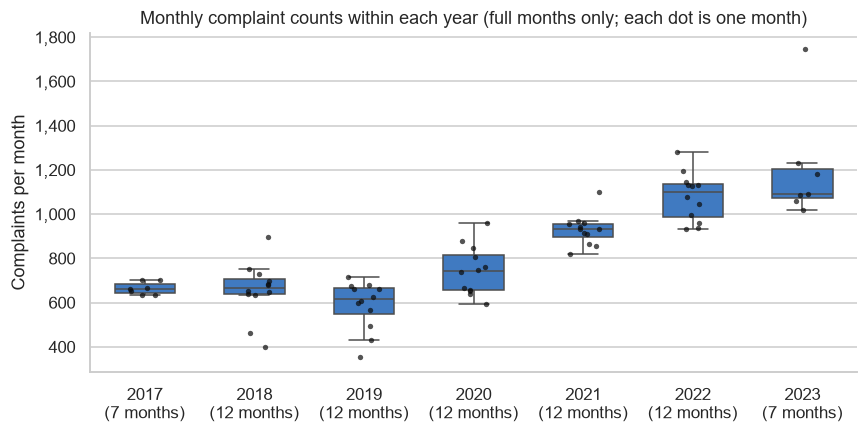

,count,mean,50%,min,max
year,,,,,
2017,7.0,664.0,661.0,635.0,701.0
2018,12.0,656.0,666.0,400.0,895.0
2019,12.0,590.0,617.0,356.0,717.0
2020,12.0,745.0,742.0,593.0,962.0
2021,12.0,929.0,934.0,821.0,1098.0
2022,12.0,1079.0,1100.0,933.0,1281.0
2023,7.0,1202.0,1092.0,1018.0,1749.0


In [22]:
full = df[~df["boundary_month"]]
by_month = full.groupby(["year", "year_month"]).size().rename("complaints").reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=by_month, x="year", y="complaints", color=BAR_COLOR, width=0.55, showfliers=False, ax=ax)
sns.stripplot(data=by_month, x="year", y="complaints", color=INK, size=3.5, alpha=0.7, jitter=0.15, ax=ax)
counts_per_year = by_month.groupby("year").size()
ax.set_xticks(range(len(counts_per_year)), [f"{y}\n({n} months)" for y, n in counts_per_year.items()])
ax.yaxis.set_major_formatter(thousands)
ax.set(xlabel="", ylabel="Complaints per month",
       title="Monthly complaint counts within each year (full months only; each dot is one month)")
save_fig(fig, "03_monthly_distribution_by_year.png")
by_month.groupby("year")["complaints"].describe()[["count", "mean", "50%", "min", "max"]].round(0)

**Volume over time (brief questions 1 and 8).**
- Monthly volume was **flat to slightly falling from 2017 to 2019** (about 590 to 670 a month), then **rose every year from 2020**: +26% in 2020, +25% in 2021, +16% in 2022 and +6% in the first eight months of 2023, on a per-month basis. By 2023 the bank received nearly **twice as many complaints a month as in 2019** (1,141 against 590).
- Raw annual totals mislead at the edges. 2023 looks like a 29.5% fall (9,131 against 12,953), but it covers only eight months; per month it is a 5.7% rise.
- Within-year spread is modest compared with the gap between years (chart 03). After 2019 the boxes barely overlap, so year-to-year differences are expected to be strong in the H1 test.
- Two irregular periods stand out. **Late 2018 to early 2019** has the lowest months in the data (356 in February 2019). **July 2023** has the highest (1,749), driven by a four-day burst on 11 to 14 July, mostly web complaints about managing or opening checking and savings accounts. Neither has an explanation in the data. Both are kept as recorded and noted when interpreting tests.

### 4.2 Products and reported issues

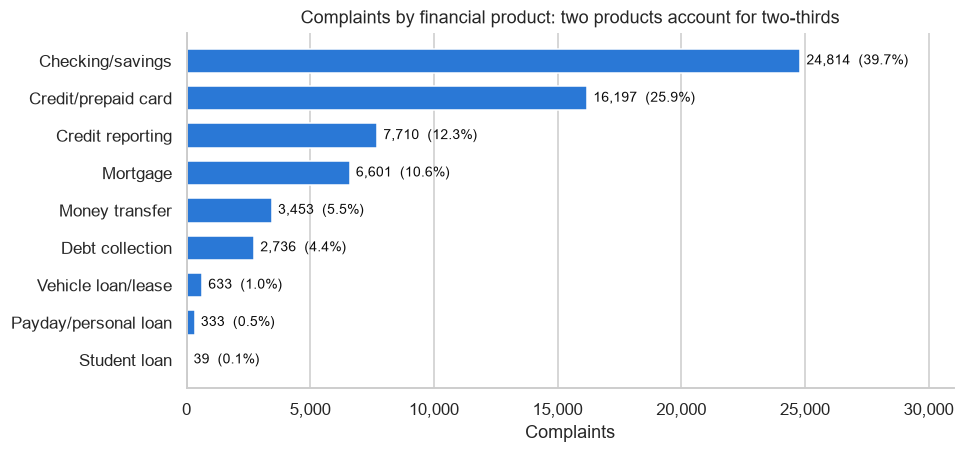

,complaints,pct
product_short,,
Checking/savings,24814,39.69
Credit/prepaid card,16197,25.91
Credit reporting,7710,12.33
Mortgage,6601,10.56
Money transfer,3453,5.52
Debt collection,2736,4.38
Vehicle loan/lease,633,1.01
Payday/personal loan,333,0.53
Student loan,39,0.06


In [23]:
products = cp.share_table(df, "product_short")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(products.index[::-1], products["complaints"][::-1], color=BAR_COLOR, height=0.65)
for y, (n, pct) in enumerate(zip(products["complaints"][::-1], products["pct"][::-1])):
    ax.text(n + products["complaints"].max() * 0.01, y, f"{n:,}  ({pct:.1f}%)", va="center", fontsize=9, color=INK)
ax.xaxis.set_major_formatter(thousands)
ax.set(xlabel="Complaints", xlim=(0, products["complaints"].max() * 1.25),
       title="Complaints by financial product: two products account for two-thirds")
ax.grid(axis="y", visible=False)
save_fig(fig, "04_complaints_by_product.png")
products

76 distinct issues; the top 12 cover 71.5% of complaints


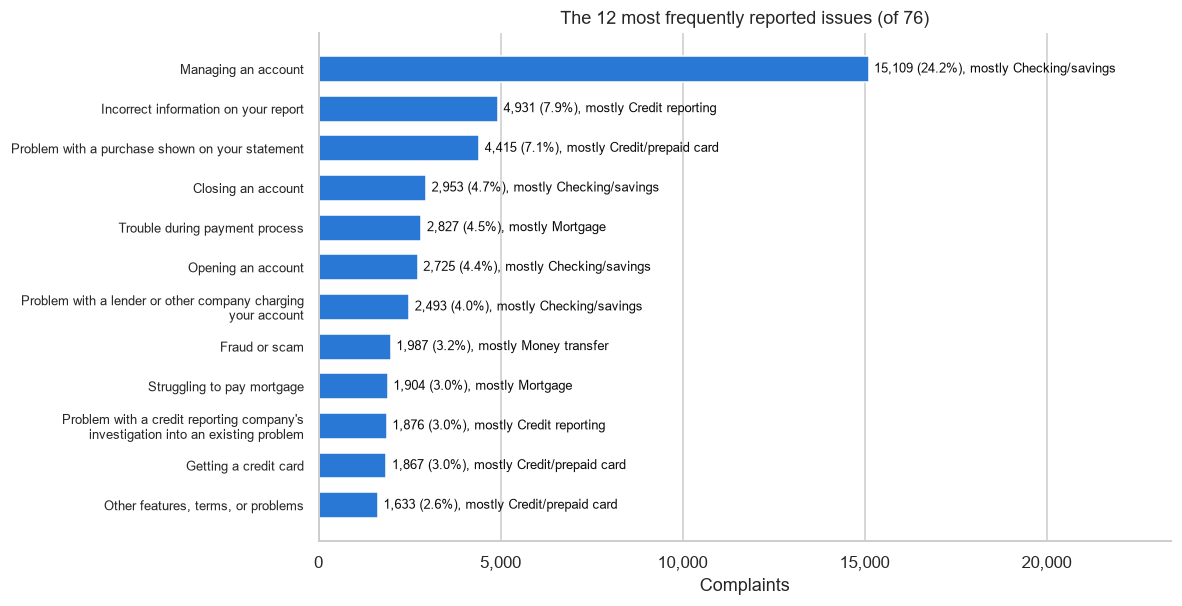

,complaints,pct,main_product,main_product_pct
Issue,,,,
Managing an account,15109,24.17,Checking/savings,100.0
Incorrect information on your report,4931,7.89,Credit reporting,84.1
Problem with a purchase shown on your statement,4415,7.06,Credit/prepaid card,100.0
Closing an account,2953,4.72,Checking/savings,100.0
Trouble during payment process,2827,4.52,Mortgage,100.0
Opening an account,2725,4.36,Checking/savings,100.0
Problem with a lender or other company charging your account,2493,3.99,Checking/savings,100.0
Fraud or scam,1987,3.18,Money transfer,98.2
Struggling to pay mortgage,1904,3.05,Mortgage,100.0


In [24]:
issues = cp.share_table(df, "Issue")
issues["main_product"] = df.groupby("Issue")["product_short"].agg(lambda s: s.value_counts().index[0])
issues["main_product_pct"] = df.groupby("Issue")["product_short"].agg(
    lambda s: round(100 * s.value_counts(normalize=True).iloc[0], 1))
issues.to_csv(OUT / "issue_share.csv")
top_issues = issues.head(12)
print(f"{len(issues)} distinct issues; the top 12 cover {top_issues['pct'].sum():.1f}% of complaints")

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh([wrap(i, 48) for i in top_issues.index[::-1]], top_issues["complaints"][::-1], color=BAR_COLOR, height=0.65)
for y, (n, pct, prod) in enumerate(zip(top_issues["complaints"][::-1], top_issues["pct"][::-1],
                                       top_issues["main_product"][::-1])):
    ax.text(n + top_issues["complaints"].max() * 0.01, y, f"{n:,} ({pct:.1f}%), mostly {prod}",
            va="center", fontsize=8.5, color=INK)
ax.tick_params(axis="y", labelsize=8.5)
ax.xaxis.set_major_formatter(thousands)
ax.set(xlabel="Complaints", xlim=(0, top_issues["complaints"].max() * 1.55),
       title=f"The 12 most frequently reported issues (of {len(issues)})")
ax.grid(axis="y", visible=False)
save_fig(fig, "05_top_issues.png")
top_issues

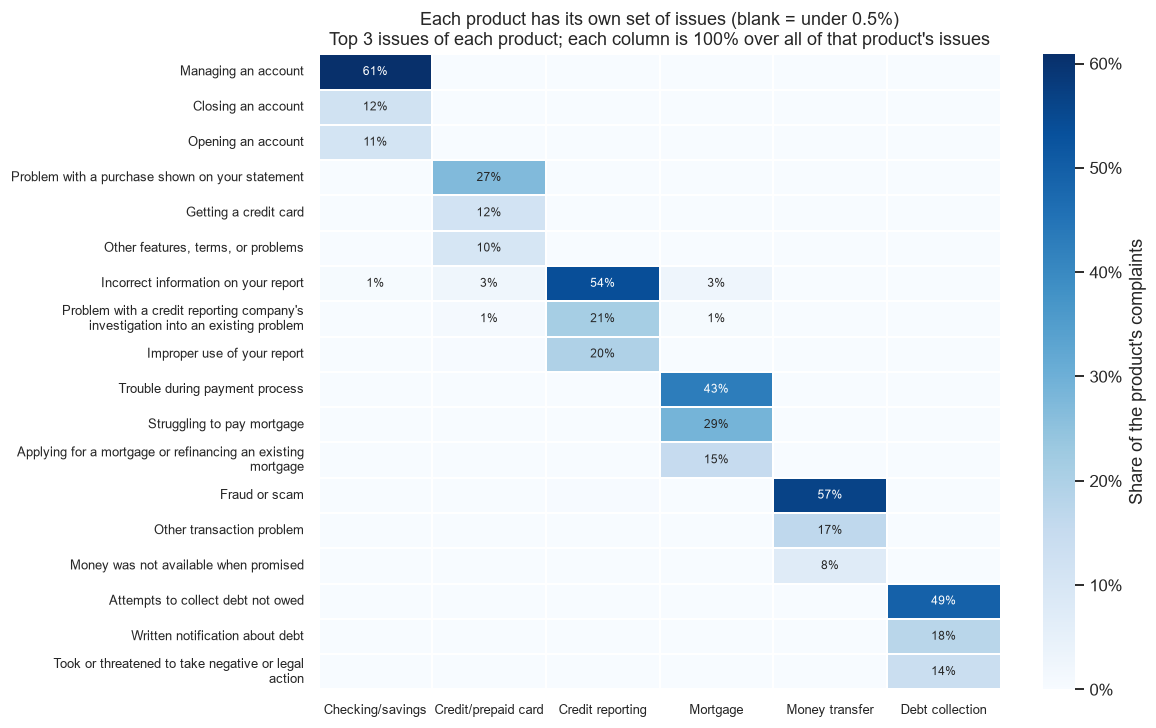

,top_issue_share,top_issue,top3_share
product_short,,,
Checking/savings,0.609,Managing an account,0.838
Credit/prepaid card,0.273,Problem with a purchase shown on your statement,0.489
Credit reporting,0.538,Incorrect information on your report,0.947
Mortgage,0.428,Trouble during payment process,0.871
Money transfer,0.565,Fraud or scam,0.806
Debt collection,0.494,Attempts to collect debt not owed,0.811


In [25]:
# Issue mix within each product: the share of each product's complaints that report each issue.
# Rows are the 3 most common issues of each of the 6 largest products, so every product is represented.
main_products = PRODUCT_ORDER[:6]
sub = df[df["product_short"].isin(main_products)]
issue_mix_all = pd.crosstab(sub["Issue"], sub["product_short"], normalize="columns")[main_products]
issue_rows = list(dict.fromkeys(
    i for p in main_products for i in sub.loc[sub["product_short"] == p, "Issue"].value_counts().index[:3]))
issue_mix = issue_mix_all.loc[issue_rows]

fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(issue_mix, cmap="Blues", vmin=0, vmax=issue_mix.max().max(), linewidths=1, linecolor="white",
            annot=issue_mix.map(lambda v: f"{v:.0%}" if v >= 0.005 else ""), fmt="", annot_kws={"fontsize": 8},
            cbar_kws={"label": "Share of the product's complaints", "format": PercentFormatter(1)}, ax=ax)
ax.set_yticklabels([wrap(i, 50) for i in issue_rows], fontsize=8.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=8.5)
ax.set(xlabel="", ylabel="",
       title="Each product has its own set of issues (blank = under 0.5%)\n"
             "Top 3 issues of each product; each column is 100% over all of that product's issues")
save_fig(fig, "06_issue_by_product.png")
issue_mix_all.max().rename("top_issue_share").to_frame().assign(
    top_issue=issue_mix_all.idxmax(), top3_share=issue_mix_all.apply(lambda c: c.nlargest(3).sum())).round(3)

**Products and issues (brief questions 2 to 4).**
- **Checking or savings accounts (39.7%) and credit or prepaid cards (25.9%) account for two-thirds of all complaints.** Credit reporting (12.3%) and mortgages (10.6%) follow. Student loans (39 complaints) and payday or personal loans (333) are too small for reliable product-level comparisons and are pooled or flagged in later tests.
- **"Managing an account" alone is 24.2% of all complaints**, more than the next three issues combined. All of them are checking or savings complaints.
- The issue list is **product-specific** (chart 06). The CFPB complaint form offers different issues for each product, so most issues appear under only one product. "Issue" and "product" are therefore not independent variables. This is why H2 compares *responses* across products instead of issues across products: an issue-by-product test would only restate the form design.
- Concentration differs. For checking/savings, one issue covers 61% of complaints, while card complaints are spread out (the top issue is only 27%).

### 4.3 How complaint patterns changed over time

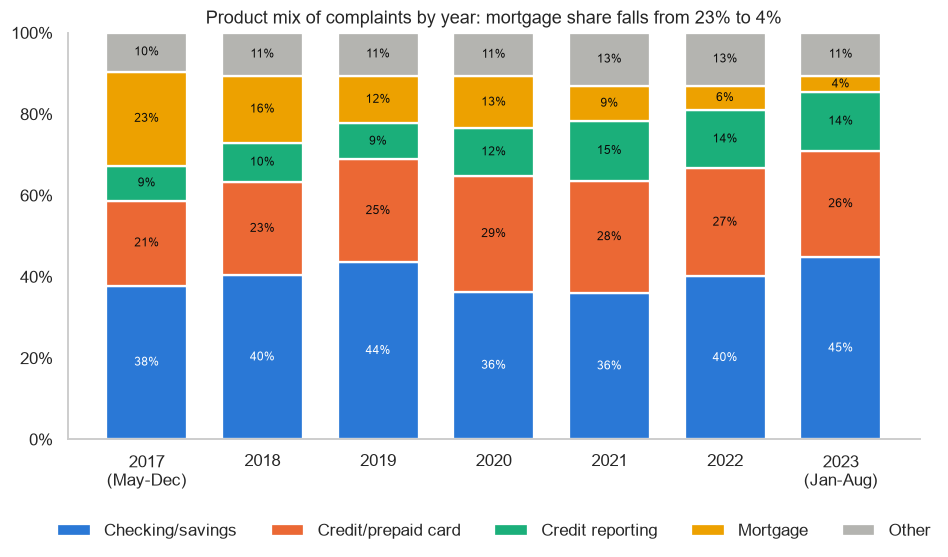

product_short,Checking/savings,Credit/prepaid card,Credit reporting,Mortgage,Other
year,,,,,
2017,37.8,20.9,8.6,23.1,9.6
2018,40.3,22.9,9.7,16.4,10.6
2019,43.5,25.3,8.9,11.7,10.6
2020,36.3,28.5,11.7,12.8,10.7
2021,35.9,27.7,14.7,8.5,13.1
2022,40.0,26.6,14.3,6.0,13.0
2023,44.7,26.3,14.4,3.9,10.7


In [26]:
product_group = df["product_short"].where(df["product_short"].isin(TOP_PRODUCTS), "Other")
product_mix = pd.crosstab(df["year"], product_group, normalize="index")[TOP_PRODUCTS + ["Other"]]
product_mix.round(4).to_csv(OUT / "product_mix_by_year.csv")

fig, ax = plt.subplots(figsize=(10, 4.8))
stacked_share_bars(ax, product_mix, SERIES + [OTHER], label_min=0.035)
ax.set_xticks(range(len(YEARS)), year_labels)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False)
ax.set(ylim=(0, 1), title="Product mix of complaints by year: mortgage share falls from 23% to 4%")
ax.grid(visible=False)
save_fig(fig, "07_product_mix_by_year.png")
(100 * product_mix).round(1)

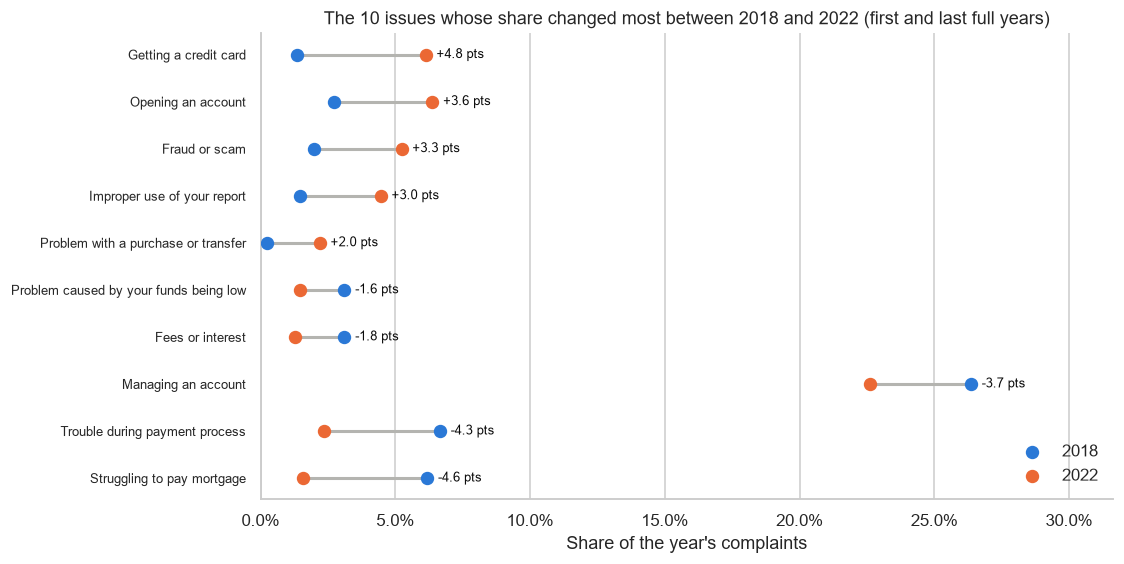

year,2018,2022,change_pts
Issue,,,
Struggling to pay mortgage,6.2,1.6,-4.6
Trouble during payment process,6.7,2.3,-4.3
Managing an account,26.4,22.6,-3.7
Fees or interest,3.1,1.3,-1.8
Problem caused by your funds being low,3.1,1.5,-1.6
Problem with a purchase or transfer,0.2,2.2,2.0
Improper use of your report,1.4,4.5,3.0
Fraud or scam,2.0,5.2,3.3
Opening an account,2.7,6.4,3.6


In [27]:
# Issue shares in the first and last full years, for the issues that moved the most
full_years = [y for y in YEARS if not annual.loc[y, "partial_year"]]
first, last = full_years[0], full_years[-1]
issue_year = pd.crosstab(df["Issue"], df["year"], normalize="columns")[[first, last]]
issue_year["change_pts"] = 100 * (issue_year[last] - issue_year[first])
movers = issue_year.reindex(issue_year["change_pts"].abs().sort_values(ascending=False).index).head(10)
movers = movers.sort_values("change_pts")

fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(movers))
ax.hlines(y, movers[first], movers[last], color=OTHER, lw=2)
ax.scatter(movers[first], y, s=60, color=SERIES[0], zorder=3, label=str(first))
ax.scatter(movers[last], y, s=60, color=SERIES[1], zorder=3, label=str(last))
for i, (a, b, d) in enumerate(zip(movers[first], movers[last], movers["change_pts"])):
    ax.text(max(a, b) + 0.004, i, f"{d:+.1f} pts", va="center", fontsize=8.5, color=INK)
ax.set_yticks(y, [wrap(i, 50) for i in movers.index], fontsize=8.5)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(xlabel="Share of the year's complaints", xlim=(0, movers[[first, last]].max().max() * 1.2),
       title=f"The 10 issues whose share changed most between {first} and {last} (first and last full years)")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
save_fig(fig, "08_issue_share_change.png")
movers[[first, last]].mul(100).round(1).assign(change_pts=movers["change_pts"].round(1))

**Changing patterns (brief question 8).**
- **Mortgage complaints shrank from 23% of the 2017 total to 4% in 2023**, and in absolute terms from about 155 a month to about 45. Mortgage payment-process and payment-hardship issues show the largest falls in issue share. Possible reasons outside the data include low interest rates and refinancing in 2020-2021, pandemic forbearance programmes, or a smaller mortgage book. The data cannot tell these apart.
- **Credit reporting rose from 9% to 14%** of complaints, together with "Improper use of your report".
- **Account-acquisition issues grew**: "Getting a credit card" (+4.8 points) and "Opening an account" (+3.6 points), along with **"Fraud or scam"** (+3.3 points, mainly money-transfer complaints). This matches the wider rise of fraud and scam complaints across the industry after 2020, but this dataset alone cannot confirm the cause.
- Because total volume nearly doubled, a falling *share* can still mean a stable or rising *count*. Checking/savings, for example, keeps a share of about 40% while its monthly count roughly doubles.

### 4.4 Recorded company responses and timeliness
A recorded response category describes how the company closed the complaint. It is **not** evidence that the consumer was satisfied or that the complaint was resolved correctly. The 1,494 *In progress* complaints (all from May to August 2023) have no outcome yet, so the response mixes below use **closed complaints only**.

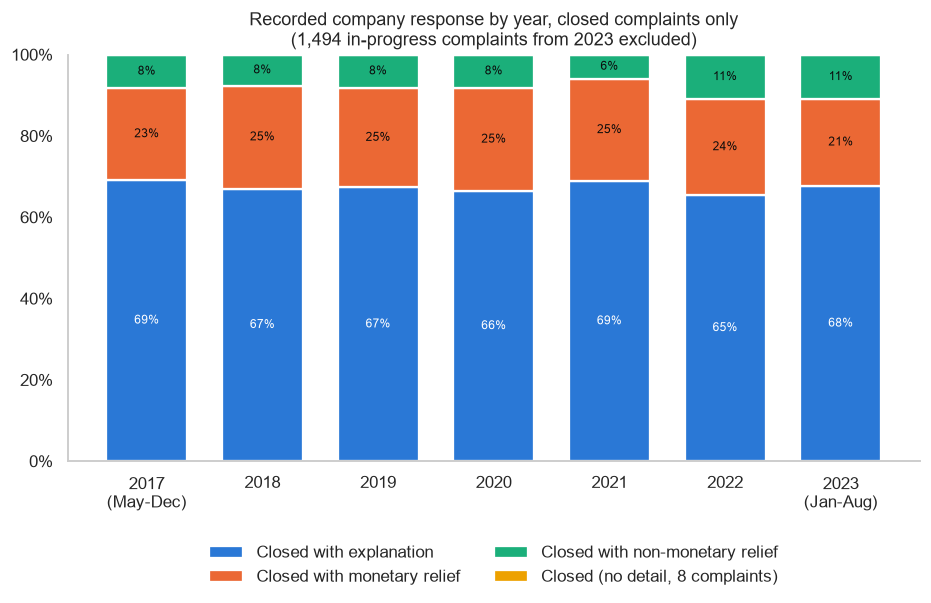

Company response to consumer,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief,Closed
year,,,,
2017,69.2,22.5,8.3,0.0
2018,67.0,25.3,7.6,0.0
2019,67.3,24.5,8.2,0.0
2020,66.5,25.3,8.2,0.0
2021,68.8,25.2,5.9,0.0
2022,65.5,23.5,11.0,0.0
2023,67.7,21.4,10.8,0.1


In [28]:
closed = df[~df["in_progress"]]
RESPONSES = ["Closed with explanation", "Closed with monetary relief", "Closed with non-monetary relief", "Closed"]
response_year = pd.crosstab(closed["year"], closed["Company response to consumer"], normalize="index")[RESPONSES]
response_year.round(4).to_csv(OUT / "response_mix_by_year.csv")

fig, ax = plt.subplots(figsize=(10, 4.8))
stacked_share_bars(ax, response_year, SERIES)
ax.set_xticks(range(len(YEARS)), year_labels)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(["Closed with explanation", "Closed with monetary relief", "Closed with non-monetary relief",
           "Closed (no detail, 8 complaints)"], ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False)
ax.set(ylim=(0, 1), title=f"Recorded company response by year, closed complaints only\n"
                          f"({df['in_progress'].sum():,} in-progress complaints from 2023 excluded)")
ax.grid(visible=False)
save_fig(fig, "09_response_mix_by_year.png")
(100 * response_year).round(1)

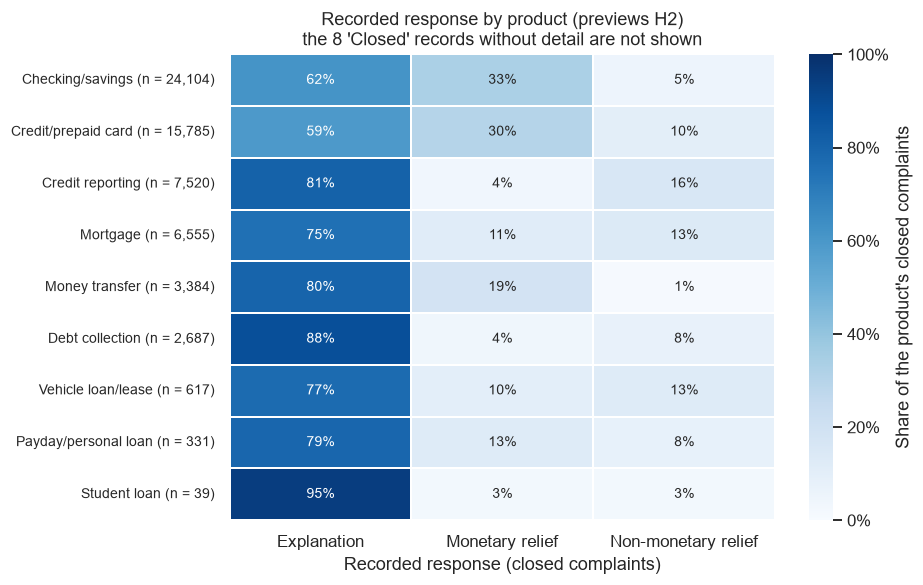

,Explanation,Monetary relief,Non-monetary relief
product_short,,,
Checking/savings,61.5,33.3,5.1
Credit/prepaid card,59.3,30.4,10.3
Credit reporting,80.7,3.6,15.7
Mortgage,75.2,11.4,13.4
Money transfer,80.1,18.7,1.2
Debt collection,88.1,4.1,7.8
Vehicle loan/lease,77.3,9.9,12.8
Payday/personal loan,79.2,12.7,8.2
Student loan,94.9,2.6,2.6


In [29]:
response_product = pd.crosstab(closed["product_short"], closed["Company response to consumer"],
                               normalize="index").loc[PRODUCT_ORDER, RESPONSES[:3]]
response_product.columns = ["Explanation", "Monetary relief", "Non-monetary relief"]
n_closed = closed["product_short"].value_counts().reindex(PRODUCT_ORDER)

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(response_product, cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".0%", annot_kws={"fontsize": 9},
            linewidths=1, linecolor="white", cbar_kws={"label": "Share of the product's closed complaints",
                                                       "format": PercentFormatter(1)}, ax=ax)
ax.set_yticklabels([f"{p} (n = {n:,})" for p, n in n_closed.items()], rotation=0, fontsize=9)
ax.set(xlabel="Recorded response (closed complaints)", ylabel="",
       title="Recorded response by product (previews H2)\n"
             "the 8 'Closed' records without detail are not shown")
save_fig(fig, "10_response_by_product.png")
(100 * response_product).round(1)

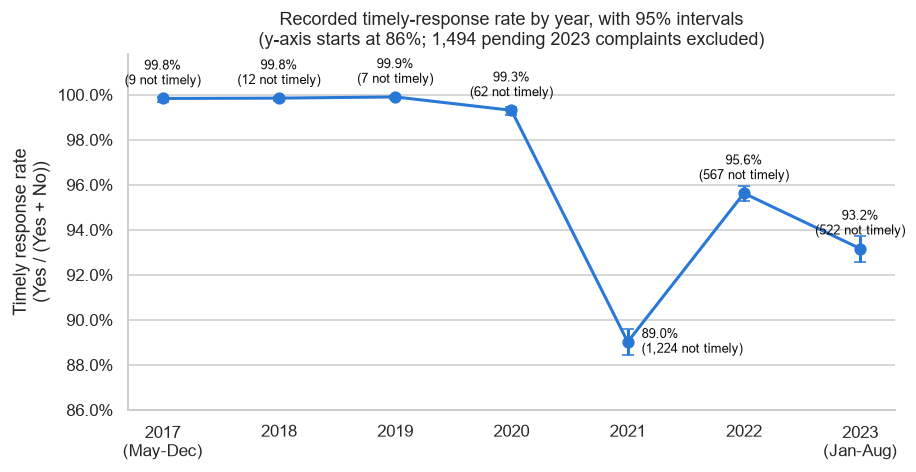

,yes,no,excluded_pending,timely_pct,ci_low_pct,ci_high_pct
year,,,,,,
2017,5385,9,0,99.83,99.68,99.91
2018,7860,12,0,99.85,99.73,99.91
2019,7068,7,0,99.90,99.80,99.95
2020,8880,62,0,99.31,99.11,99.46
2021,9925,1224,0,89.02,88.43,89.59
2022,12386,567,0,95.62,95.26,95.96
2023,7115,522,1494,93.16,92.58,93.71


In [30]:
timely_year = pd.DataFrame([{"year": y, **cp.timely_rate(g)} for y, g in df.groupby("year")]).set_index("year")
# 95% Wilson interval for each year's timely rate
z = 1.96
p_hat, n_den = timely_year["yes"] / timely_year["denominator"], timely_year["denominator"]
centre = (p_hat + z**2 / (2 * n_den)) / (1 + z**2 / n_den)
half = z * np.sqrt(p_hat * (1 - p_hat) / n_den + z**2 / (4 * n_den**2)) / (1 + z**2 / n_den)
timely_year["ci_low_pct"], timely_year["ci_high_pct"] = 100 * (centre - half), 100 * (centre + half)
timely_year.round(2).to_csv(OUT / "timely_rate_by_year.csv")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.errorbar(range(len(timely_year)), timely_year["timely_pct"],
            yerr=[timely_year["timely_pct"] - timely_year["ci_low_pct"], timely_year["ci_high_pct"] - timely_year["timely_pct"]],
            color=BAR_COLOR, lw=2, marker="o", ms=7, capsize=4)
for i, (pct, no) in enumerate(zip(timely_year["timely_pct"], timely_year["no"])):
    above = pct > 92
    ax.text(i + (0 if above else 0.12), pct + (0.45 if above else 0), f"{pct:.1f}%\n({no:,} not timely)",
            ha="center" if above else "left", va="bottom" if above else "center", fontsize=8.5, color=INK)
ax.set_xticks(range(len(YEARS)), year_labels)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set(ylabel="Timely response rate\n(Yes / (Yes + No))", ylim=(86, 101.8),
       title="Recorded timely-response rate by year, with 95% intervals\n"
             f"(y-axis starts at 86%; {timely_year['excluded_pending'].sum():,} pending 2023 complaints excluded)")
ax.grid(axis="x", visible=False)
save_fig(fig, "11_timely_rate_by_year.png")
timely_year[["yes", "no", "excluded_pending", "timely_pct", "ci_low_pct", "ci_high_pct"]].round(2)

In [31]:
# When did untimely responses start, and which products were affected?
decided = df[df["timely"].notna()]
untimely_q = decided.groupby("year_quarter")["timely"].agg(
    decided="size", not_timely=lambda s: int((s == False).sum()))  # noqa: E712
untimely_q["not_timely_pct"] = (100 * untimely_q["not_timely"] / untimely_q["decided"]).round(1)
untimely_q["pending"] = df.groupby("year_quarter")["in_progress"].sum()
print("Untimely responses by quarter, 2020 Q3 onwards:")
display(untimely_q.loc["2020Q3":].T)
print("Timely rate by product in 2021 (%):")
(100 * decided[decided["year"] == 2021].groupby("product_short")["timely"].mean().astype(float)
 ).reindex(PRODUCT_ORDER).round(1).to_frame("timely_pct_2021").T

Untimely responses by quarter, 2020 Q3 onwards:


year_quarter,2020Q3,2020Q4,2021Q1,2021Q2,2021Q3,2021Q4,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2,2023Q3
decided,2206,2686,3006,2721,2689,2733,3077,2948,3519,3409,3504,3117,1016
not_timely,11,41,4,419,510,291,103,53,169,242,399,123,0
not_timely_pct,0.5,1.5,0.1,15.4,19.0,10.6,3.3,1.8,4.8,7.1,11.4,3.9,0.0
pending,0,0,0,0,0,0,0,0,0,0,0,44,1450


Timely rate by product in 2021 (%):


product_short,Checking/savings,Credit/prepaid card,Credit reporting,Mortgage,Money transfer,Debt collection,Vehicle loan/lease,Payday/personal loan,Student loan
timely_pct_2021,92.2,87.4,81.4,99.6,89.6,80.5,88.5,92.1,100.0


**Responses and timeliness (brief questions 6 to 8).**
- **"Closed with explanation" is the most frequent recorded response (67% of closed complaints)**, followed by monetary relief (24%) and non-monetary relief (9%). The mix is **stable from year to year**: explanation stays between 65% and 69%. The only visible shift is non-monetary relief rising from about 8% to 11% in 2022-2023.
- The response mix differs **much more by product than by year** (chart 10). A third of checking/savings and card complaints closed with monetary relief, against 4% for credit reporting and debt collection. That fits the products: account and card disputes often involve a fee or charge that can be refunded, while credit reporting disputes are usually fixed by correcting a record. H2 tests this.
- **The timely-response rate was 99.3% to 99.9% from 2017 to 2020, then fell to 89.0% in 2021** (1,224 untimely responses, half of all untimely responses in the dataset). The drop starts in **Q2 2021** and affects every product except mortgages (99.6% timely). It partly recovered to 95.6% in 2022. The data does not say why; a company-wide operational change is more consistent with this pattern than a problem in one product. H3 tests it.
- **The 2023 rate (93.2%) is provisional.** No complaint from Q3 2023 has been marked untimely yet because those complaints are still in progress. Once they close, some may turn out untimely, so the 2023 figure can only fall or stay the same. It is right-censored, not a like-for-like comparison.

### 4.5 CFPB forwarding intervals
The forwarding interval is `Date received` minus `Date submitted`: the days the **CFPB** took to send the complaint to the company. It says nothing about how quickly the company responded.

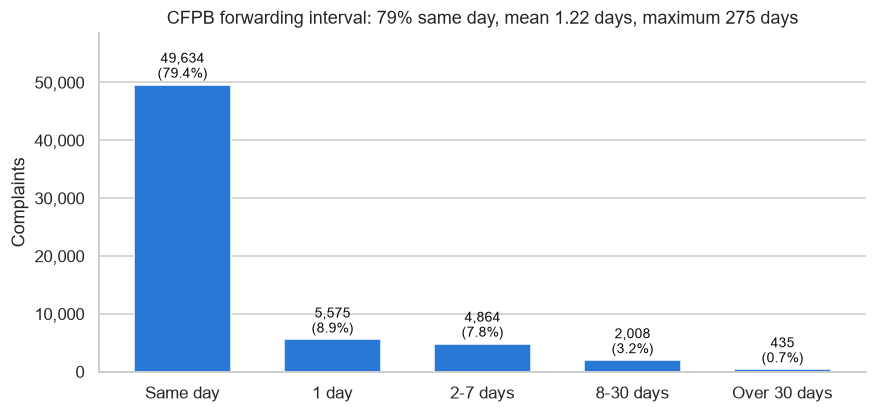

n               62516.00
mean_days           1.22
median_days         0.00
p95_days            5.00
max_days          275.00
same_day_pct       79.39
long_count        435.00


In [32]:
FWD_BINS = [-1, 0, 1, 7, 30, np.inf]
FWD_LABELS = ["Same day", "1 day", "2-7 days", "8-30 days", f"Over {cp.LONG_FORWARDING_DAYS} days"]
fwd_band = pd.cut(df["forwarding_days"], FWD_BINS, labels=FWD_LABELS)
bands = fwd_band.value_counts().reindex(FWD_LABELS)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(FWD_LABELS, bands.values, color=BAR_COLOR, width=0.65)
for i, n in enumerate(bands.values):
    ax.text(i, n + bands.max() * 0.01, f"{n:,}\n({n / len(df):.1%})", ha="center", va="bottom", fontsize=9, color=INK)
ax.yaxis.set_major_formatter(thousands)
ax.set(ylabel="Complaints", ylim=(0, bands.max() * 1.18),
       title=f"CFPB forwarding interval: {forwarding['same_day_pct']:.0f}% same day, mean {forwarding['mean_days']:.2f} days, "
             f"maximum {forwarding['max_days']} days")
ax.grid(axis="x", visible=False)
save_fig(fig, "12_forwarding_distribution.png")
print(pd.Series({k: round(v, 2) for k, v in forwarding.items()}).to_string())

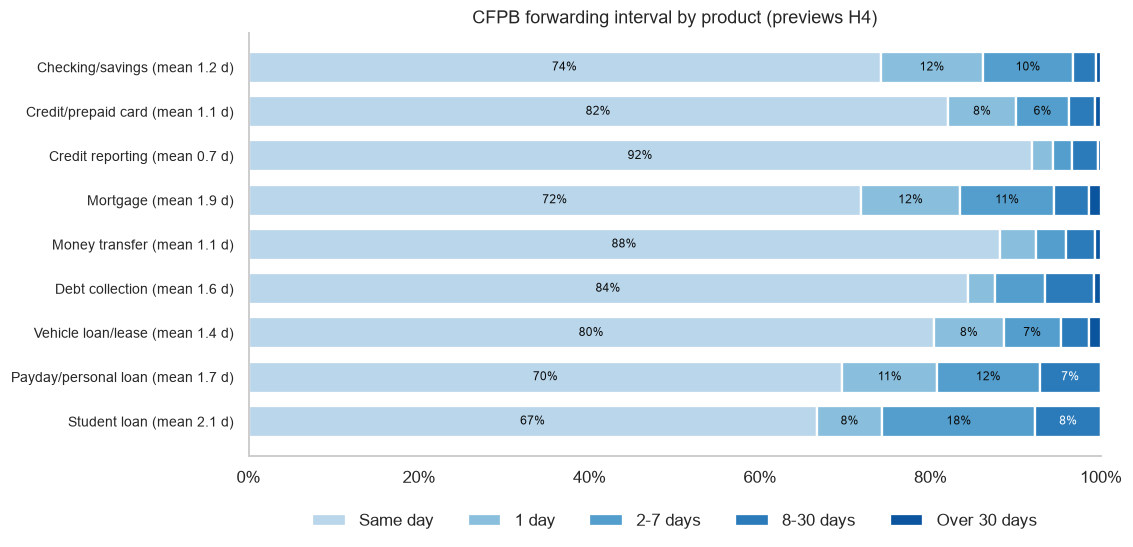

,complaints,mean_days,median_days,p95_days,same_day_pct,long_count
product_short,,,,,,
Checking/savings,24814,1.23,0.0,5.0,74.15,156
Credit/prepaid card,16197,1.13,0.0,5.0,82.04,105
Credit reporting,7710,0.74,0.0,3.0,91.88,25
Mortgage,6601,1.86,0.0,9.0,71.87,93
Money transfer,3453,1.06,0.0,5.0,88.13,26
Debt collection,2736,1.64,0.0,10.0,84.36,21
Vehicle loan/lease,633,1.44,0.0,5.8,80.41,9
Payday/personal loan,333,1.68,0.0,10.4,69.67,0
Student loan,39,2.13,0.0,12.0,66.67,0


In [33]:
fwd_product = df.groupby("product_short").agg(
    complaints=("forwarding_days", "size"), mean_days=("forwarding_days", "mean"),
    median_days=("forwarding_days", "median"), p95_days=("forwarding_days", lambda s: s.quantile(0.95)),
    same_day_pct=("same_day_forwarding", lambda s: 100 * s.mean()), long_count=("long_forwarding", "sum"),
).loc[PRODUCT_ORDER]
fwd_product.round(2).to_csv(OUT / "forwarding_by_product.csv")
band_mix = pd.crosstab(df["product_short"], fwd_band, normalize="index").loc[PRODUCT_ORDER, FWD_LABELS]

# The bands are ordered, so they use one hue from light to dark instead of categorical colours
ramp = sns.color_palette("Blues", len(FWD_LABELS) + 1).as_hex()[1:]
fig, ax = plt.subplots(figsize=(10, 5))
stacked_share_bars(ax, band_mix, ramp, label_min=0.06, horizontal=True)
ax.set_yticks(range(len(PRODUCT_ORDER)),
              [f"{p} (mean {m:.1f} d)" for p, m in zip(PRODUCT_ORDER, fwd_product["mean_days"])], fontsize=9)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
ax.set(xlim=(0, 1), title="CFPB forwarding interval by product (previews H4)")
ax.grid(visible=False)
save_fig(fig, "13_forwarding_by_product.png")
fwd_product.round(2)

In [34]:
# Unusually long forwarding intervals (> 30 days): where and when they occur
long = df[df["long_forwarding"]]
long_summary = pd.DataFrame({
    "long_count": long["year"].value_counts().sort_index(),
    "pct_of_year": (100 * df.groupby("year")["long_forwarding"].mean()).round(2),
    "mean_days_all": df.groupby("year")["forwarding_days"].mean().round(2),
    "same_day_pct_all": (100 * df.groupby("year")["same_day_forwarding"].mean()).round(1),
}).fillna(0)
long_summary.to_csv(OUT / "forwarding_by_year.csv")
print("Long intervals by submission channel:")
display(pd.DataFrame({"long_count": long["Submitted via"].value_counts(),
                      "pct_of_channel": (100 * df.groupby("Submitted via")["long_forwarding"].mean()).round(2)})
        .fillna(0).astype({"long_count": int}).sort_values("long_count", ascending=False))
long_summary

Long intervals by submission channel:


,long_count,pct_of_channel
Submitted via,,
Referral,207,1.92
Web,162,0.36
Phone,57,1.22
Postal mail,9,0.68
Email,0,0.00
Fax,0,0.00
Web Referral,0,0.00


,long_count,pct_of_year,mean_days_all,same_day_pct_all
year,,,,
2017,45,0.83,1.24,74.1
2018,82,1.04,1.62,69.9
2019,102,1.44,1.77,74.7
2020,12,0.13,0.71,77.4
2021,34,0.30,1.26,76.6
2022,46,0.36,1.10,85.2
2023,114,1.25,1.08,91.4


**Forwarding intervals (brief question 5).**
- The CFPB forwards most complaints quickly: **79.4% the same day, 88% within one day, mean 1.22 days, median 0**. The distribution is extremely right-skewed (95th percentile 5 days, maximum 275), so the **median and the same-day share describe it better than the mean**. H4 uses rank-based tests for this reason.
- **By product**, credit reporting is fastest (92% same day, mean 0.7 days) and mortgages slowest among the large products (72%, mean 1.9 days). The differences are small in days. H4 will check whether they matter in practice, not only whether they are significant.
- **By year**, same-day forwarding improved from about 70-75% in 2017-2019 to 91% in 2023.
- **Long intervals (over 30 days, 435 complaints)** are concentrated in **referrals** (1.9% of referral complaints, against 0.4% of web complaints). A referred complaint comes to the CFPB from another agency, so extra routing steps are a likely, though unconfirmed, explanation. Long intervals were most common in 2018-2019 and again in 2023.

### 4.6 EDA summary: what the tests in Section 5 need to check
| Pattern seen | Tested in |
|---|---|
| Monthly volume roughly doubled from 2019 to 2023 | H1 (Kruskal-Wallis across years, Mann-Kendall trend) |
| Monetary relief is far more common for account and card complaints | H2 (chi-square, Cramér's V) |
| Timely rate fell sharply in 2021 and only partly recovered | H3 (chi-square with residuals; 2023 provisional) |
| Forwarding speed differs slightly by product | H4 (Kruskal-Wallis with ε², same-day share) |